In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Dataset/student_performance_1000.csv')

In [ ]:
df.head()

,Study_Hours,Attendance_Percentage,Previous_Exam_Marks,Assignment_Marks,Performance
0,4.4,59.3,50.7,80.4,Average
1,9.6,77.1,49.8,87.8,Excellent
2,7.6,93.6,89.4,55.0,Excellent
3,6.4,86.6,50.0,77.5,Very Good
4,2.4,90.3,51.3,74.3,Poor


In [ ]:
df.shape

(1000, 5)

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Study_Hours            1000 non-null   float64
 1   Attendance_Percentage  1000 non-null   float64
 2   Previous_Exam_Marks    1000 non-null   float64
 3   Assignment_Marks       1000 non-null   float64
 4   Performance            1000 non-null   object 
dtypes: float64(4), object(1)
memory usage: 39.2+ KB


In [ ]:
df.describe()

,Study_Hours,Attendance_Percentage,Previous_Exam_Marks,Assignment_Marks
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,5.413500,75.351200,65.144300,69.422900
std,2.630701,14.608042,17.440426,17.190604
min,1.000000,50.200000,35.000000,40.000000
25%,3.100000,62.075000,50.675000,54.500000
50%,5.500000,75.950000,65.000000,69.050000
75%,7.700000,88.000000,80.525000,84.225000
max,10.000000,100.000000,94.900000,100.000000


In [ ]:
X = df.iloc[:,:-1]
y = df['Performance']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)

In [ ]:
model = LogisticRegression(
    multi_class='multinomial',
    solver='lbfgs',
    max_iter=200
)
model.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=200, multi_class='multinomial')

In [ ]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.68

Confusion Matrix:
 [[26  0 12  9  1]
 [ 0 31  0  0  3]
 [12  0 19  0  8]
 [ 5  0  0 37  0]
 [ 0  9  5  0 23]]

Classification Report:
               precision    recall  f1-score   support

     Average       0.60      0.54      0.57        48
   Excellent       0.78      0.91      0.84        34
        Good       0.53      0.49      0.51        39
        Poor       0.80      0.88      0.84        42
   Very Good       0.66      0.62      0.64        37

    accuracy                           0.68       200
   macro avg       0.67      0.69      0.68       200
weighted avg       0.67      0.68      0.67       200



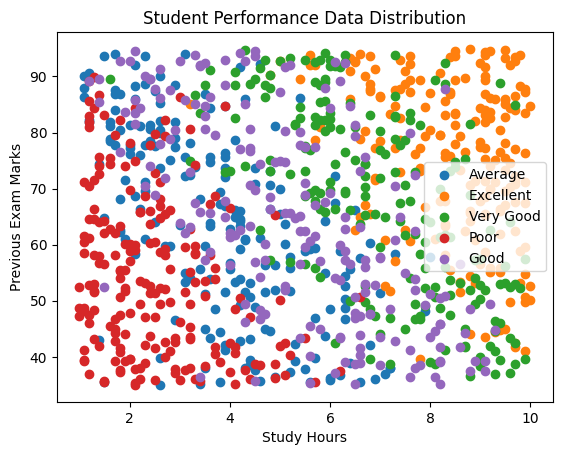

In [ ]:
import matplotlib.pyplot as plt

# Feature names for visualization
x_feature = 'Study_Hours'
y_feature = 'Previous_Exam_Marks'

# Plot each class separately
for class_value in df['Performance'].unique():
    plt.scatter(
        df.loc[df['Performance'] == class_value, x_feature],
        df.loc[df['Performance'] == class_value, y_feature],
        label=class_value
    )

# Labels and title
plt.xlabel("Study Hours")
plt.ylabel("Previous Exam Marks")
plt.title("Student Performance Data Distribution")

plt.legend()
plt.show()

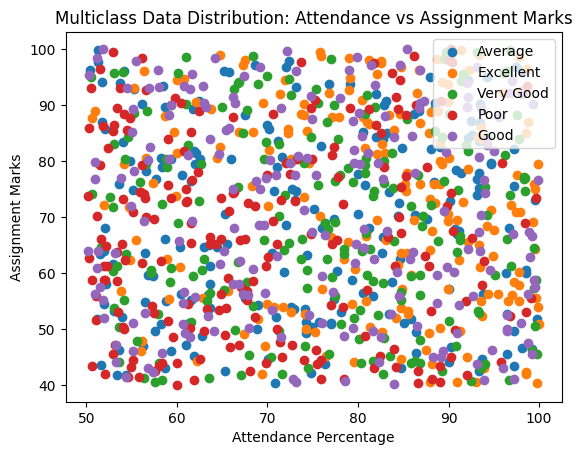

In [ ]:
# Feature names
x_feature = 'Attendance_Percentage'
y_feature = 'Assignment_Marks'

# Plot data for each class
for class_value in df['Performance'].unique():
    plt.scatter(
        df.loc[df['Performance'] == class_value, x_feature],
        df.loc[df['Performance'] == class_value, y_feature],
        label=class_value
    )

# Plot formatting
plt.xlabel("Attendance Percentage")
plt.ylabel("Assignment Marks")
plt.title("Multiclass Data Distribution: Attendance vs Assignment Marks")
plt.legend()
plt.show()

In [ ]:
import pickle

In [ ]:
pickle.dump(model,open('StdModel.pkl','wb'))